# Notebook 3 — Build a FODO ring

In this first exercise, use the tools introduced in the introductory notebooks to **build an electron storage ring from identical FODO cells**. 

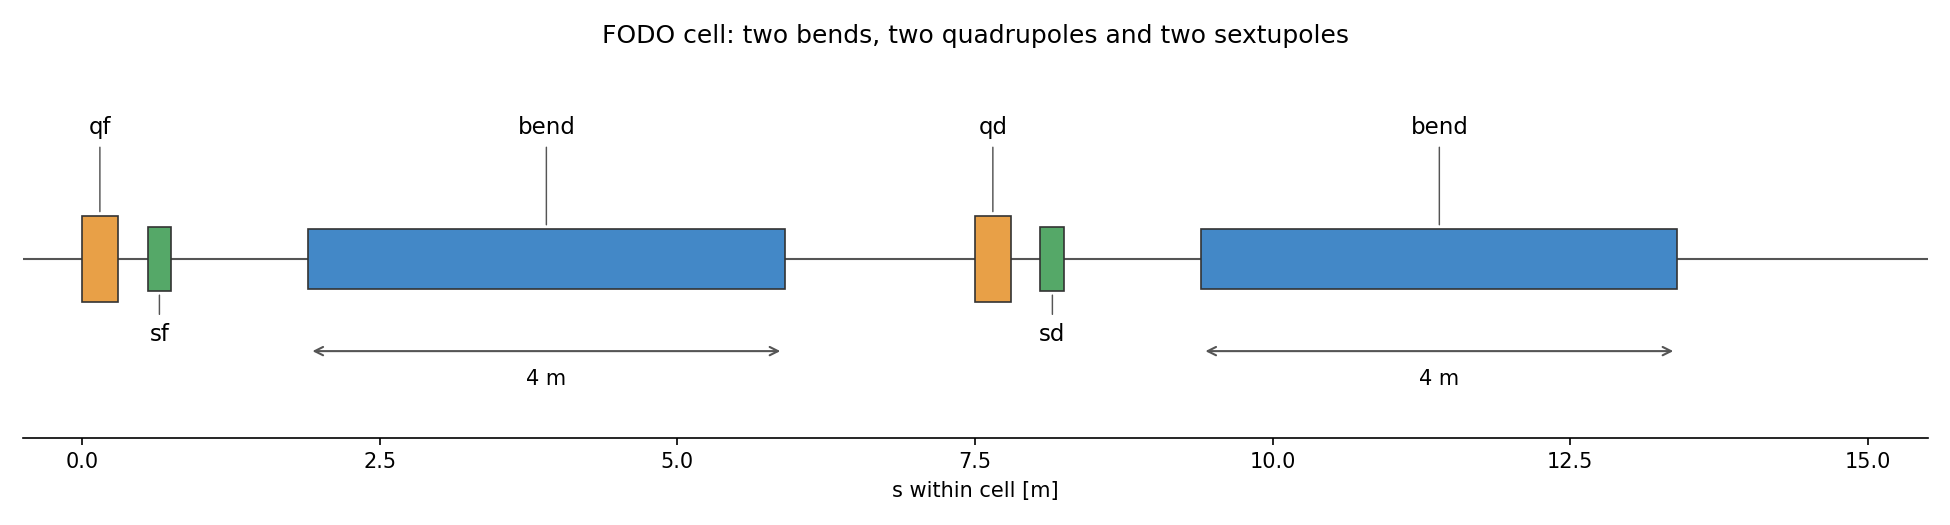

Magnet lengths and positions are to scale.

## Lattice specifications

| Parameter | Value |
|---|---:|
| Reference particle | Electron |
| Reference total energy | 1.7 GeV |
| Ring circumference | 240 m |
| Number of identical FODO cells | 16 |
| Cell length | 15 m |
| Dipole type | Sector bend (`xt.Bend`) |
| Dipole length | 4.0 m |
| Quadrupole length | 0.30 m |
| Sextupole length | 0.20 m |
| Ring chromaticity targets | 0.5 / 0.5 |

### Create the environment and define the parameters

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

In [2]:
env = xt.Environment()
env.set_particle_ref('electron', energy0=1.7e9)

n_cells = 16
n_bends = 2 * n_cells

env['l_cell'] = 15.0
env['l_bend'] = 4.0
env['l_quad'] = 0.30
env['l_sext'] = 0.20
env['angle_bend'] = 2 * np.pi / n_bends

env['kqf'] = 0.0
env['kqd'] = 0.0

env['ksf'] = 0.0
env['ksd'] = 0.0

### Define the magnets and build the cell

In [3]:
# Define elements
env.new('qf', xt.Quadrupole, length='l_quad', k1='kqf')
env.new('qd', xt.Quadrupole, length='l_quad', k1='kqd')
env.new('bend', xt.Bend, length='l_bend', angle='angle_bend', k1=0)
env.new('sf', xt.Sextupole, length='l_sext', k2='ksf')
env.new('sd', xt.Sextupole, length='l_sext', k2='ksd')

'sd'

In [4]:
# Define cell
cell = env.new_line(length=env['l_cell'], components=[
    env.place('qf',   at='l_quad/2'),
    env.place('sf',   at='l_quad/2 + 0.50'),
    env.place('bend', at='l_quad/2 + l_cell/4'),
    env.place('qd',   at='l_quad/2 + l_cell/2'),
    env.place('sd',   at='l_quad/2 + l_cell/2 + 0.50'),
    env.place('bend', at='l_quad/2 + 3*l_cell/4'),
])

### Survey the cell

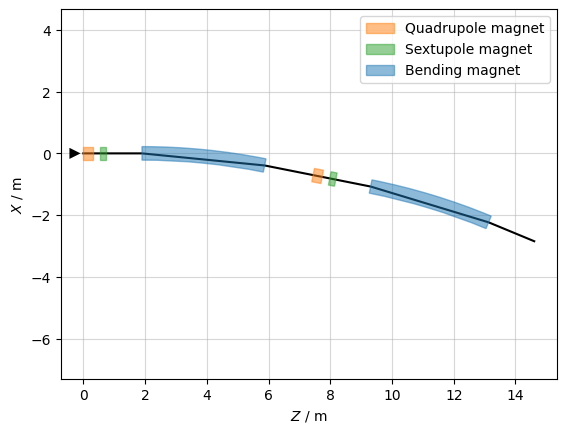

In [5]:
sv_cell = cell.survey()
sv_cell.plot()

### Set weak quadrupole strengths and calculate the optics

In [6]:
env['kqf'] = 0.10
env['kqd'] = -0.10

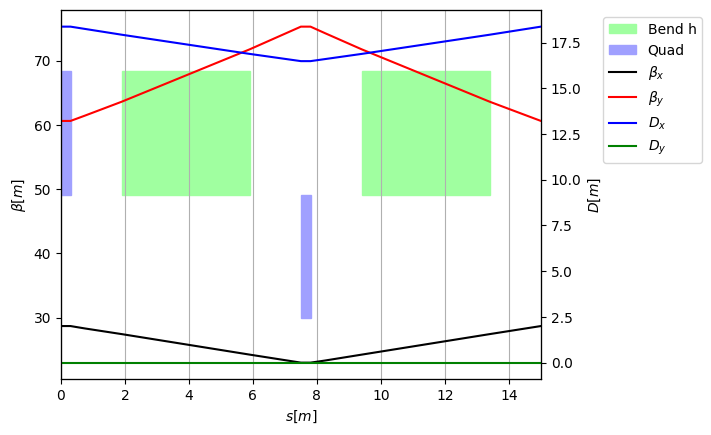

In [7]:
tw_cell = cell.twiss4d()
tw_cell.plot()

### Match the cell phase advances

In [8]:
opt_cell = cell.match(
    solve=False,
    method='4d',
    vary=[
        xt.Vary('kqf', limits=(0, 10), step=1e-3),
        xt.Vary('kqd', limits=(-10, 0), step=1e-3),
    ],
    targets=[
        xt.TargetSet(qx=91 / 360, qy=92 / 360, tol=1e-6),
    ],
)

In [9]:
opt_cell.target_status()

Target status:               alty = 2.7215e+00              
id state tag tol_met       residue   current_val    target_val description                             
0  ON    qx    False     -0.159998     0.0927799      0.252778 'qx', val=0.252778, tol=1e-06, weight=10
1  ON    qy    False     -0.220153     0.0354021      0.255556 'qy', val=0.255556, tol=1e-06, weight=10


In [10]:
opt_cell.run_jacobian(30)

                                             
Optimize - start penalty: 2.722                             
Matching: model call n. 23 penalty = 1.0714e-09              
Optimize - end penalty:  1.07141e-09                            


In [11]:
opt_cell.target_status()
opt_cell.vary_status()

Target status:               nalty = 1.0714e-09              
id state tag tol_met       residue   current_val    target_val description                             
0  ON    qx     True   6.51909e-11      0.252778      0.252778 'qx', val=0.252778, tol=1e-06, weight=10
1  ON    qy     True  -8.50253e-11      0.255556      0.255556 'qy', val=0.255556, tol=1e-06, weight=10
Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kqf            0      0.612724          10           0.1         0.001             1
1  ON        OK  kqd          -10     -0.642094           0          -0.1         0.001             1


### Inspect the matched cell optics

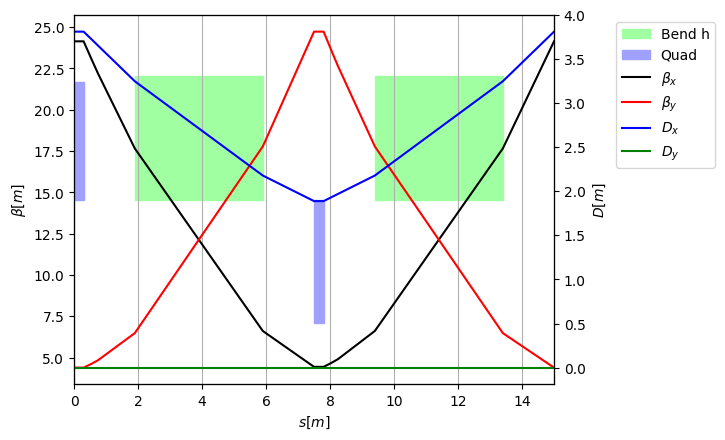

In [12]:
tw_cell = cell.twiss4d()
tw_cell.plot()

### Assemble the ring

In [13]:
ring = n_cells * cell
ring.replace_all_repeated_elements()

### Survey

In [14]:
sv = ring.survey()

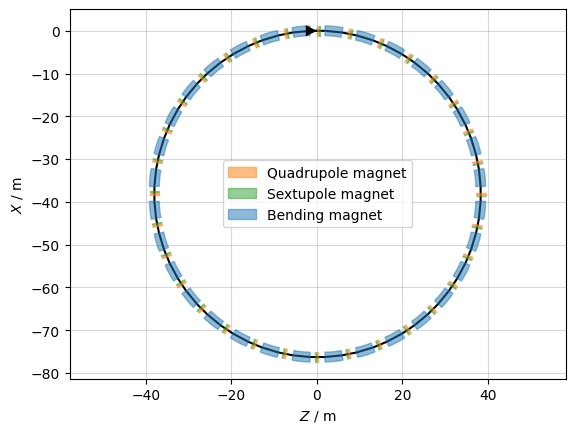

In [15]:
sv.plot()

### Full-ring optics

Ring tunes: 4.0444 / 4.0889


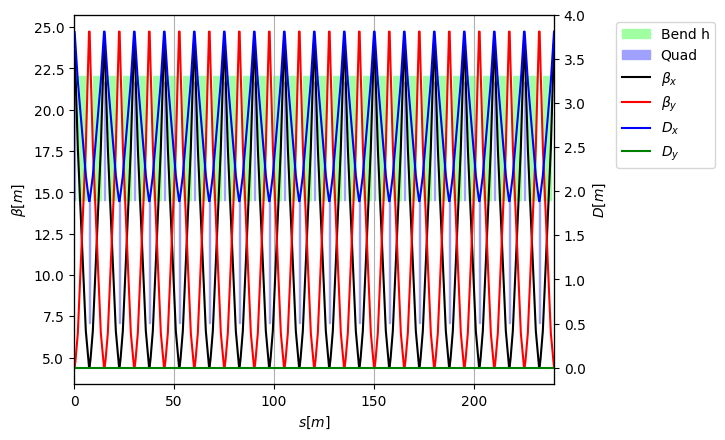

In [16]:
tw_ring = ring.twiss4d()
print(f'Ring tunes: {tw_ring.qx:.4f} / {tw_ring.qy:.4f}')
tw_ring.plot()

### Correct the chromaticities

In [17]:
opt_chrom = ring.match(
    solve=False,
    method='4d',
    vary=xt.VaryList(['ksf', 'ksd'], step=1e-3),
    targets=xt.TargetSet(dqx=0.5, dqy=0.5, tol=1e-6),
)

In [18]:
opt_chrom.target_status()

Target status:               alty = 7.0281e+00              
id state tag tol_met       residue   current_val    target_val description                        
0  ON    dqx   False      -4.67848      -4.17848           0.5 'dqx', val=0.5, tol=1e-06, weight=1
1  ON    dqy   False      -5.24465      -4.74465           0.5 'dqy', val=0.5, tol=1e-06, weight=1


In [19]:
opt_chrom.run_jacobian(10)

                                             
Optimize - start penalty: 7.028                             
Matching: model call n. 23 penalty = 5.3664e-07              
Optimize - end penalty:  5.36639e-07                            


In [20]:
opt_chrom.target_status()
opt_chrom.vary_status()

Target status:               nalty = 5.3664e-07              
id state tag tol_met       residue   current_val    target_val description                        
0  ON    dqx    True  -5.36639e-07      0.499999           0.5 'dqx', val=0.5, tol=1e-06, weight=1
1  ON    dqy    True  -1.94289e-11           0.5           0.5 'dqy', val=0.5, tol=1e-06, weight=1
Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  ksf  None             0.284099 None                    0         0.001             1
1  ON        OK  ksd  None            -0.567146 None                    0         0.001             1


In [21]:
tw_ring = ring.twiss4d()
print(f'Ring tunes: {tw_ring.qx:.4f} / {tw_ring.qy:.4f}')
print(f'Chromaticities: {tw_ring.dqx:.3e} / {tw_ring.dqy:.3e}')

Ring tunes: 4.0444 / 4.0889
Chromaticities: 5.000e-01 / 5.000e-01


### Radiation integrals

See the [radiation-integral outputs in the Xsuite reference](https://xsuite.readthedocs.io/en/latest/apireference.html).

In [22]:
ring_rad = ring.copy()
ring_rad.slice_thick_elements(slicing_strategies=[
    xt.Strategy(slicing=None),
    xt.Strategy(slicing=xt.Uniform(8, mode='thick'), element_type=xt.Bend),
    xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
])

tw_rad = ring_rad.twiss4d(radiation_integrals=True)

Slicing line:   0%|          | 0/192 [00:00<?, ?it/s]

### Energy loss, damping times, and equilibrium beam parameters

In [23]:
tw_rad.rad_int_energy_loss # eV

36268.196444923975

In [24]:
tw_rad.rad_int_damping_constant_x_s # [1/s]

11.587285883274104

In [25]:
tw_rad.rad_int_damping_constant_y_s # [1/s]

13.324671273836538

In [26]:
tw_rad.rad_int_damping_constant_zeta_s # [1/s]

28.38672793823551

In [27]:
tw_rad.rad_int_sigma_delta

0.0003126034158225385

In [28]:
tw_rad.rad_int_eq_gemitt_x * 1e9 # [nm rad]

160.49689912441156

In [29]:
tw_rad.rad_int_eq_gemitt_y * 1e9 # [nm rad]

3.797672425526546e-46

### Curly H and the $I_5$ integrand

$$
\mathcal{H}=\gamma D^2+2\alpha DD'+\beta D'^2,
\qquad I_5=\oint\frac{\mathcal{H}}{|\rho|^3}\,ds.
$$

(0.0, 0.8138028032738761)

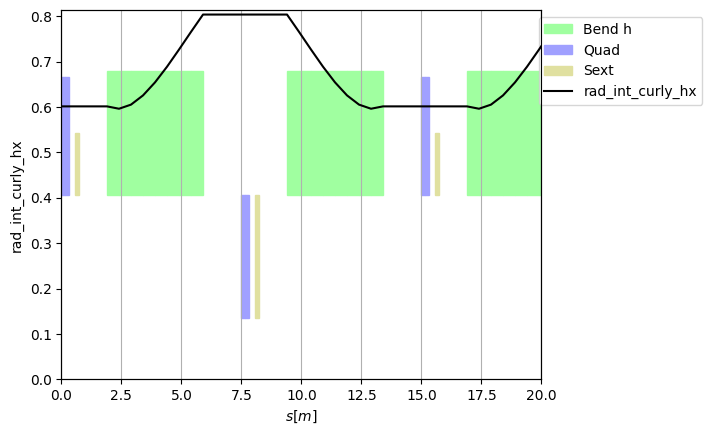

In [30]:
tw_rad.plot('rad_int_curly_hx')
plt.xlim(0, 20)
plt.ylim(0, None)

(0.0, 20.0)

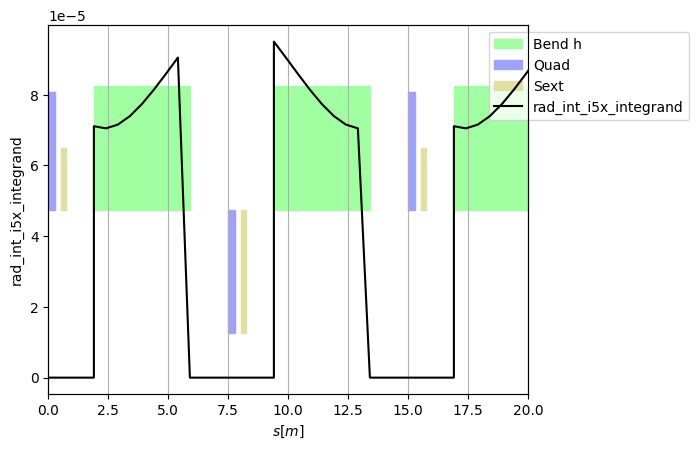

In [31]:
tw_rad.plot('rad_int_i5x_integrand')
plt.xlim(0, 20)

### Save the matched ring

Save the ring with its matched quadrupole and sextupole strengths for the dynamic-aperture exercise.

In [32]:
ring.to_json('ring_fodo.json')